## Part 1: Setup and Data Loading

Load Fashion-MNIST with torchvision, split 60k → 50k train / 10k val,
and normalize with mean 0.2860, std 0.3530 (Fashion-MNIST global stats).

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import seaborn as sns
import os
import time
import json

# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


### Data loading and splitting

We use the standard Fashion-MNIST normalization values:
mean = 0.2860, std = 0.3530 (computed across the training set).

In [2]:
# Transform: convert to tensor + normalize
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

# Download training set (60,000 images)
full_train = datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=transform
)

# Download test set (10,000 images) — will be used as a held-out set
test_set = datasets.FashionMNIST(
    root='./data', train=False, download=True, transform=transform
)

# Split 60k → 50k train / 10k val
train_set, val_set = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

print(f"Train set: {len(train_set)} samples")
print(f"Validation set: {len(val_set)} samples")
print(f"Test set: {len(test_set)} samples")

Train set: 50000 samples
Validation set: 10000 samples
Test set: 10000 samples


### DataLoaders

Batch size 64 for the baseline. We'll see how batch size affects
performance in Part 3.

In [3]:
BATCH_SIZE = 64


train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=BATCH_SIZE, shuffle=False)

# Inspect one batch
images, labels = next(iter(train_loader))
print(f"Batch shape: {images.shape}")
print(f"Labels shape: {labels.shape}")
print(f"Pixel value range: [{images.min():.3f}, {images.max():.3f}]")

Batch shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
Pixel value range: [-0.810, 2.023]


### Class names

In [4]:
CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

### Visualise some samples

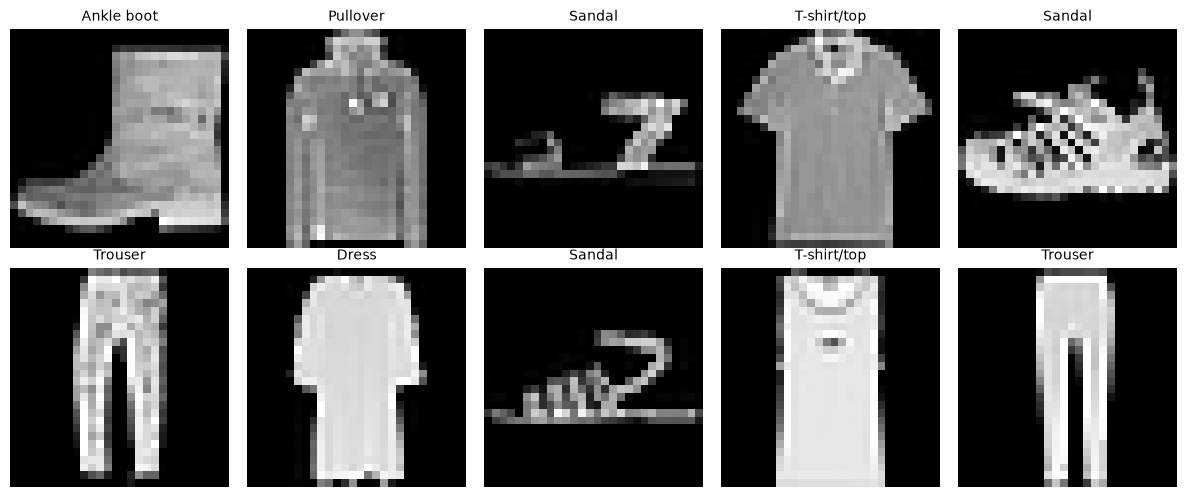

Saved sample_images.png


In [5]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flatten()):
    img, lbl = train_set[i]
    # Undo normalization for display
    img_display = img.squeeze() * 0.3530 + 0.2860
    ax.imshow(img_display, cmap='gray')
    ax.set_title(CLASS_NAMES[lbl], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.savefig('sample_images.png', dpi=100)
plt.show()
print("Saved sample_images.png")

## Part 2: Baseline MLP

Architecture: 784 → 128 (ReLU) → 64 (ReLU) → 10
Trained for 10 epochs with SGD, lr=0.01, batch_size=64.

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cpu


### Reuse data setup

In [7]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

full_train = datasets.FashionMNIST(root='./data', train=True,
                                   download=True, transform=transform)
train_set, val_set = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size=64, shuffle=False)

### Network Architecture

In [8]:
class MLP(nn.Module):
    """
    Simple MLP for Fashion-MNIST.
    784 -> 128 -> 64 -> 10, with ReLU activations.
    """
    def __init__(self, dropout=0.0):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()

    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x

# Sanity check
model_test = MLP()
x_dummy = torch.randn(4, 1, 28, 28)
print(f"Output shape: {model_test(x_dummy).shape}")

Output shape: torch.Size([4, 10])


### Training loop

In [9]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    """
    Trains a model and validates it each epoch.
    Returns history dict with train_loss, val_loss, val_acc per epoch.
    """
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    model = model.to(device)

    print("Starting Training...")
    for epoch in range(epochs):
        # Training
        model.train()
        running_train_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * images.size(0)

        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        history['train_loss'].append(epoch_train_loss)

        # Validation
        model.eval()
        running_val_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * images.size(0)

                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = correct / total

        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {epoch_train_loss:.4f}, "
              f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

    print("Finished Training")
    return history

### Train the baseline

In [10]:
baseline_model = MLP()
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(baseline_model.parameters(), lr=0.01)

baseline_history = train_model(
    baseline_model, train_loader, val_loader,
    criterion, optimizer, epochs=10
)

baseline_acc = baseline_history['val_acc'][-1]
print(f"\nBaseline final validation accuracy: {baseline_acc:.4f}")

Starting Training...


Epoch 1/10 - Train Loss: 0.9819, Val Loss: 0.6151, Val Acc: 0.7818


Epoch 2/10 - Train Loss: 0.5320, Val Loss: 0.5321, Val Acc: 0.8073


Epoch 3/10 - Train Loss: 0.4689, Val Loss: 0.4784, Val Acc: 0.8339


Epoch 4/10 - Train Loss: 0.4370, Val Loss: 0.4476, Val Acc: 0.8400


...

Epoch 6/10 - Train Loss: 0.3974, Val Loss: 0.4123, Val Acc: 0.8518


Epoch 7/10 - Train Loss: 0.3837, Val Loss: 0.4075, Val Acc: 0.8529


Epoch 8/10 - Train Loss: 0.3720, Val Loss: 0.4042, Val Acc: 0.8551


Epoch 9/10 - Train Loss: 0.3617, Val Loss: 0.3746, Val Acc: 0.8651


Epoch 10/10 - Train Loss: 0.3521, Val Loss: 0.4009, Val Acc: 0.8549
Finished Training

Baseline final validation accuracy: 0.8549


### Plot the baseline loss curves

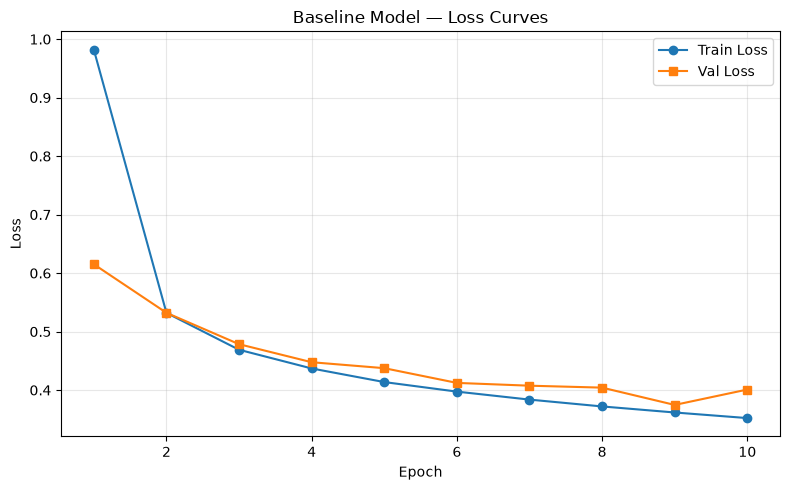

Saved baseline_loss_curves.png


In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
epochs = range(1, 11)
ax.plot(epochs, baseline_history['train_loss'], marker='o', label='Train Loss')
ax.plot(epochs, baseline_history['val_loss'], marker='s', label='Val Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Baseline Model — Loss Curves')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('baseline_loss_curves.png', dpi=100)
plt.show()
print("Saved baseline_loss_curves.png")

## Part 3: Hyperparameter Optimisation

Grid search over three hyperparameters:
- Learning rate: {0.001, 0.01, 0.1}
- Batch size: {32, 64, 128}
- Dropout: {0.0, 0.2, 0.5}

That's 27 combinations, each trained for 10 epochs.

**Note:** If `part3_results.csv` exists, we load the cached results instead of
re-running the (95-minute) grid search. This keeps notebook re-runs fast.

In [12]:
if os.path.exists('part3_results.csv') and os.path.exists('part3_histories.json'):
    print("Loading cached results from part3_results.csv")
    df = pd.read_csv('part3_results.csv')
    with open('part3_histories.json') as f:
        all_histories = json.load(f)
    print(f"Loaded {len(df)} runs from cache")
else:
    print("No cache found — running full grid search (~95 min)")
    learning_rates = [0.001, 0.01, 0.1]
    batch_sizes = [32, 64, 128]
    dropouts = [0.0, 0.2, 0.5]
    results = []
    all_histories = {}
    total_runs = len(learning_rates) * len(batch_sizes) * len(dropouts)
    run_id = 0
    start_time = time.time()

    for lr in learning_rates:
        for bs in batch_sizes:
            for do in dropouts:
                run_id += 1
                key = f"lr{lr}_bs{bs}_do{do}"
                print(f"\n[{run_id}/{total_runs}] {key}")

                train_loader = DataLoader(train_set, batch_size=bs, shuffle=True)
                val_loader = DataLoader(val_set, batch_size=bs, shuffle=False)

                torch.manual_seed(42)
                model = MLP(dropout=do)
                criterion = nn.CrossEntropyLoss()
                optimizer = optim.SGD(model.parameters(), lr=lr)

                t0 = time.time()
                hist = train_model(model, train_loader, val_loader,
                                   criterion, optimizer, epochs=10)
                elapsed = time.time() - t0

                print(f"   Final val acc: {hist['val_acc'][-1]:.4f}  "
                      f"(best: {max(hist['val_acc']):.4f})  Time: {elapsed:.1f}s")

                results.append({
                    'lr': lr, 'batch_size': bs, 'dropout': do,
                    'final_val_acc': hist['val_acc'][-1],
                    'best_val_acc': max(hist['val_acc']),
                    'train_time_s': elapsed
                })
                all_histories[key] = hist

    df = pd.DataFrame(results)
    df.to_csv('part3_results.csv', index=False)
    with open('part3_histories.json', 'w') as f:
        json.dump(all_histories, f)
    print(f"\nTotal time: {(time.time() - start_time)/60:.1f} min")
    print(df.to_string(index=False))

Loading cached results from part3_results.csv
Loaded 27 runs from cache


In [13]:
# Show the top-performing configurations
print("\n=== Results sorted by best val acc ===")
print(df.sort_values('best_val_acc', ascending=False).head(10).to_string(index=False))

best_row = df.loc[df['best_val_acc'].idxmax()]
print(f"\nBest observed configuration:")
print(f"  lr         = {best_row['lr']}")
print(f"  batch_size = {best_row['batch_size']}")
print(f"  dropout    = {best_row['dropout']}")
print(f"  Best val acc = {best_row['best_val_acc']:.4f}")


=== Results sorted by best val acc ===
  lr  batch_size  dropout  final_val_acc  best_val_acc  train_time_s
0.10          32      0.0         0.8787        0.8842    220.670421
0.10         128      0.0         0.8816        0.8830    201.425048
0.10         128      0.2         0.8810        0.8810    204.942715
0.10          32      0.2         0.8780        0.8789    232.865298
0.01          32      0.0         0.8779        0.8779    220.284226
0.01          32      0.2         0.8779        0.8779    231.110678
0.10          64      0.0         0.8605        0.8753    207.473502
0.10          64      0.2         0.8744        0.8750    211.792190
0.10          32      0.5         0.8724        0.8724    226.169215
0.10         128      0.5         0.8665        0.8698    203.862070

Best observed configuration:
  lr         = 0.1
  batch_size = 32.0
  dropout    = 0.0
  Best val acc = 0.8842


## Part 4: Analysis and Report

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import json

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

### Load results from Part 3

In [15]:
df = pd.read_csv('part3_results.csv')
print(df.head())
print(f"\nBest final config: {df.loc[df['final_val_acc'].idxmax()].to_dict()}")
print(f"Best observed config: {df.loc[df['best_val_acc'].idxmax()].to_dict()}")

with open('part3_histories.json', 'r') as f:
    histories = json.load(f)

      lr  batch_size  dropout  final_val_acc  best_val_acc  train_time_s
0  0.001          32      0.0         0.8246        0.8246    220.121545
1  0.001          32      0.2         0.8156        0.8156    223.900641
2  0.001          32      0.5         0.7864        0.7864    233.809835
3  0.001          64      0.0         0.7888        0.7888    206.489911
4  0.001          64      0.2         0.7729        0.7729    210.562434

Best final config: {'lr': 0.1, 'batch_size': 128.0, 'dropout': 0.0, 'final_val_acc': 0.8816, 'best_val_acc': 0.883, 'train_time_s': 201.4250481128693}
Best observed config: {'lr': 0.1, 'batch_size': 32.0, 'dropout': 0.0, 'final_val_acc': 0.8787, 'best_val_acc': 0.8842, 'train_time_s': 220.67042112350464}


### Table for the report

In [16]:
print("\n=== Full Results Table ===")
print(df.to_string(index=False))


=== Full Results Table ===
   lr  batch_size  dropout  final_val_acc  best_val_acc  train_time_s
0.001          32      0.0         0.8246        0.8246    220.121545
0.001          32      0.2         0.8156        0.8156    223.900641
0.001          32      0.5         0.7864        0.7864    233.809835
0.001          64      0.0         0.7888        0.7888    206.489911
0.001          64      0.2         0.7729        0.7729    210.562434
0.001          64      0.5         0.7442        0.7442    210.792747
0.001         128      0.0         0.7468        0.7468    199.547842
0.001         128      0.2         0.7348        0.7348    202.784343
0.001         128      0.5         0.7182        0.7190    203.063120
0.010          32      0.0         0.8779        0.8779    220.284226
0.010          32      0.2         0.8779        0.8779    231.110678
0.010          32      0.5         0.8645        0.8645    227.389448
0.010          64      0.0         0.8586        0.8586    206

### Visualisation 1: Hyperparameter impact heatmap

We'll show three heatmaps — one per (batch_size, dropout) pair — with
learning rate on the x-axis. Easier to compare.

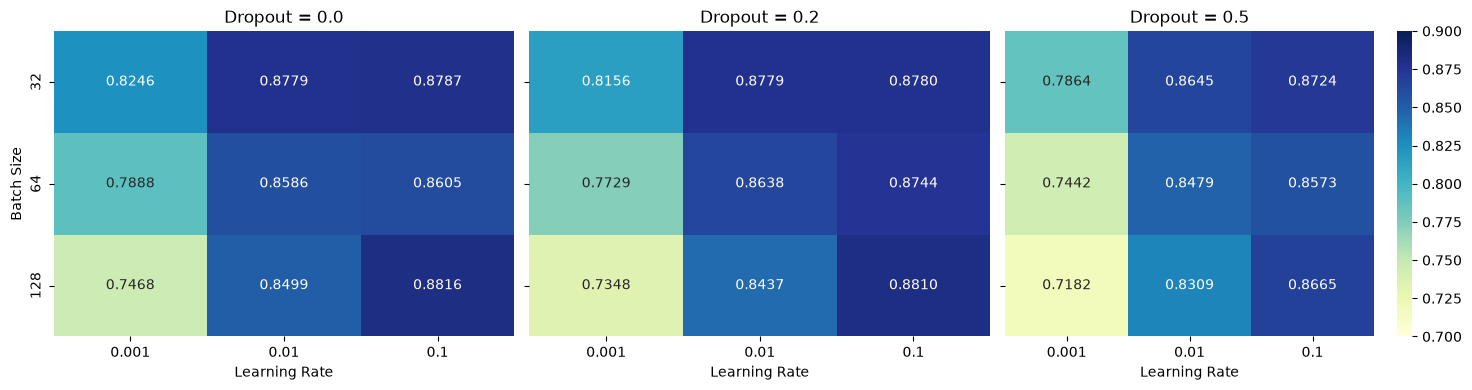

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
pivot_dropouts = [0.0, 0.2, 0.5]

for ax, do in zip(axes, pivot_dropouts):
    sub = df[df['dropout'] == do]
    pivot = sub.pivot(index='batch_size', columns='lr', values='final_val_acc')
    sns.heatmap(pivot, annot=True, fmt='.4f', cmap='YlGnBu',
                vmin=0.70, vmax=0.90, ax=ax, cbar=(do == 0.5))
    ax.set_title(f'Dropout = {do}')
    ax.set_xlabel('Learning Rate')
    ax.set_ylabel('Batch Size' if do == 0.0 else '')

plt.tight_layout()
plt.savefig('fig_hyperparam_heatmap.png', dpi=100)
plt.show()

### Visualisation 2: Bar chart — best per learning rate

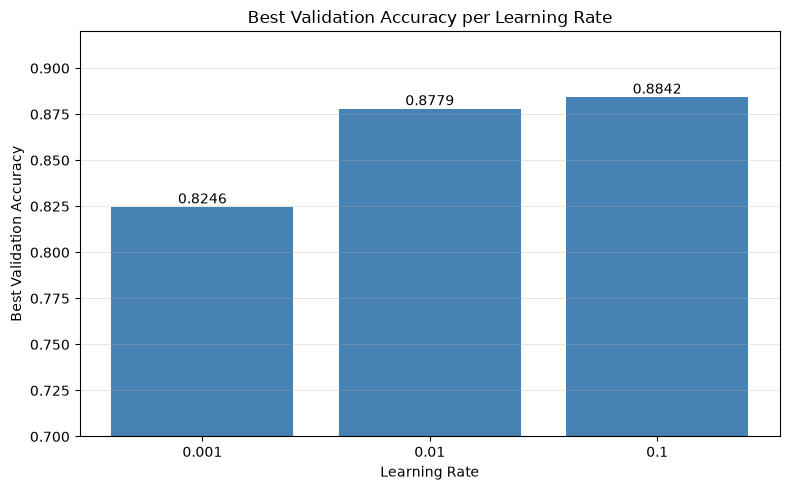

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
best_per_lr = df.groupby('lr')['best_val_acc'].max()
ax.bar(best_per_lr.index.astype(str), best_per_lr.values, color='steelblue')
for i, v in enumerate(best_per_lr.values):
    ax.text(i, v + 0.002, f'{v:.4f}', ha='center')
ax.set_xlabel('Learning Rate')
ax.set_ylabel('Best Validation Accuracy')
ax.set_title('Best Validation Accuracy per Learning Rate')
ax.set_ylim(0.70, 0.92)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('fig_lr_impact.png', dpi=100)
plt.show()

### Train baseline + best model with identical setup for loss-curve comparison

In [19]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])
full_train = datasets.FashionMNIST(root='./data', train=True,
                                   download=True, transform=transform)
train_set, val_set = random_split(
    full_train, [50000, 10000],
    generator=torch.Generator().manual_seed(42)
)

class MLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
    def forward(self, x):
        x = self.flatten(x)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        return self.fc3(x)

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    model = model.to(device)
    for epoch in range(epochs):
        model.train()
        running = 0.0
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            out = model(imgs)
            loss = criterion(out, lbls)
            loss.backward()
            optimizer.step()
            running += loss.item() * imgs.size(0)
        history['train_loss'].append(running / len(train_loader.dataset))
        model.eval()
        rv, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                out = model(imgs)
                rv += criterion(out, lbls).item() * imgs.size(0)
                correct += (out.argmax(1) == lbls).sum().item()
                total += lbls.size(0)
        history['val_loss'].append(rv / len(val_loader.dataset))
        history['val_acc'].append(correct / total)
    return history

# Baseline
train_loader_b = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader_b = DataLoader(val_set, batch_size=64, shuffle=False)
baseline_model = MLP(dropout=0.0)
baseline_hist = train_model(baseline_model, train_loader_b, val_loader_b,
                            nn.CrossEntropyLoss(),
                            optim.SGD(baseline_model.parameters(), lr=0.01),
                            epochs=10)
print(f"Baseline final val acc: {baseline_hist['val_acc'][-1]:.4f}")

# Best
train_loader_best = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader_best = DataLoader(val_set, batch_size=32, shuffle=False)
best_model = MLP(dropout=0.0)
best_hist = train_model(best_model, train_loader_best, val_loader_best,
                        nn.CrossEntropyLoss(),
                        optim.SGD(best_model.parameters(), lr=0.1),
                        epochs=10)
print(f"Best model final val acc: {best_hist['val_acc'][-1]:.4f}")

Baseline final val acc: 0.8586


Best model final val acc: 0.8882


### Visualisation 3: Loss curves — baseline vs best

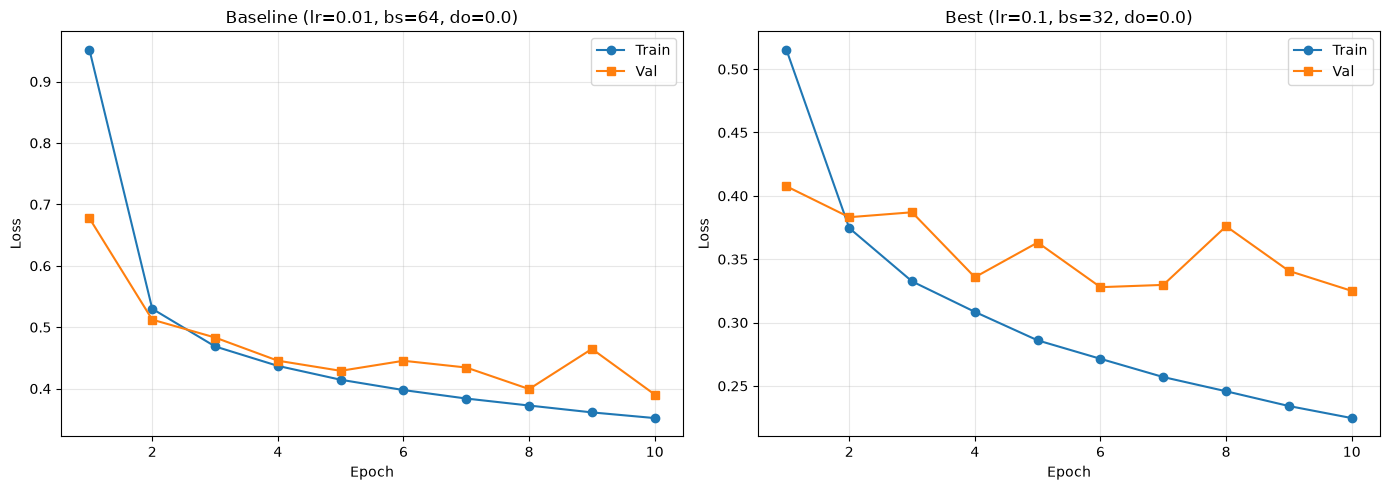

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs = range(1, 11)

axes[0].plot(epochs, baseline_hist['train_loss'], 'o-', label='Train')
axes[0].plot(epochs, baseline_hist['val_loss'], 's-', label='Val')
axes[0].set_title('Baseline (lr=0.01, bs=64, do=0.0)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, best_hist['train_loss'], 'o-', label='Train')
axes[1].plot(epochs, best_hist['val_loss'], 's-', label='Val')
axes[1].set_title('Best (lr=0.1, bs=32, do=0.0)')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('fig_loss_curves.png', dpi=100)
plt.show()

### Visualisation 4: Confusion matrix for best model

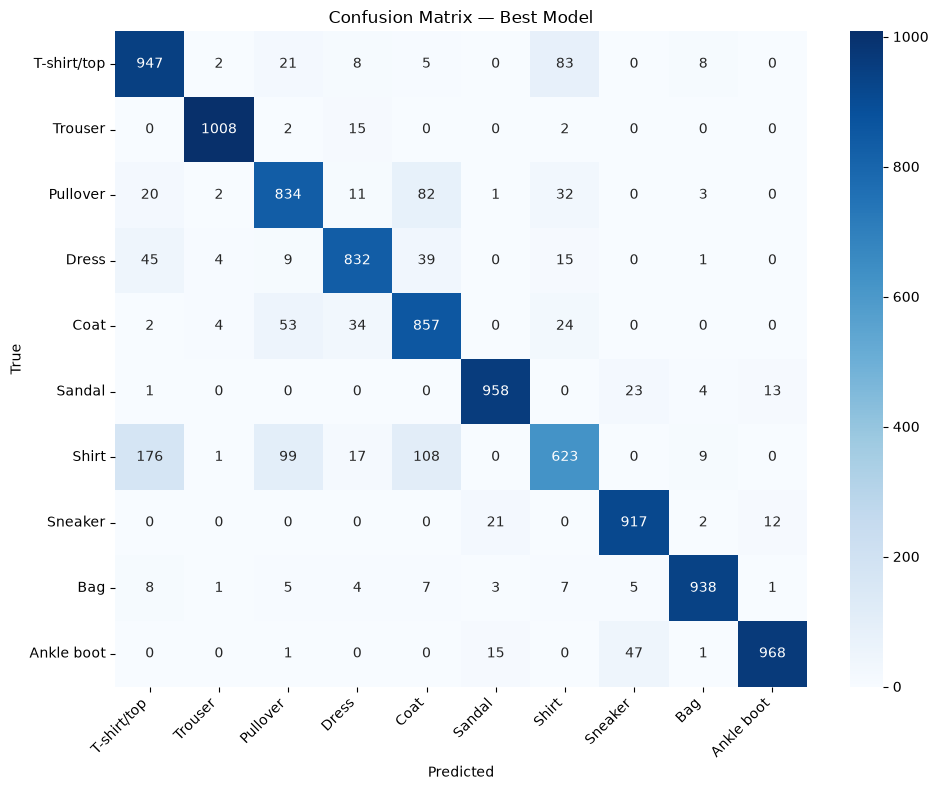

In [21]:
best_model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader_best:
        imgs = imgs.to(device)
        preds = best_model(imgs).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(lbls.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix — Best Model')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('fig_confusion_matrix.png', dpi=100)
plt.show()

### Which classes are confused?

In [22]:
# Off-diagonal top confusions
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
flat_idx = np.argsort(cm_off.flatten())[::-1][:6]
print("\nTop 6 confused pairs (true → predicted):")
for idx in flat_idx:
    i, j = idx // 10, idx % 10
    if cm_off[i, j] > 0:
        print(f"  {CLASS_NAMES[i]:>12} → {CLASS_NAMES[j]:<12} : {cm_off[i, j]} times")


Top 6 confused pairs (true → predicted):
         Shirt → T-shirt/top  : 176 times
         Shirt → Coat         : 108 times
         Shirt → Pullover     : 99 times
   T-shirt/top → Shirt        : 83 times
      Pullover → Coat         : 82 times
          Coat → Pullover     : 53 times
